# Retail Sales Analysis

This notebook analyzes the provided Kaggle retail sales dataset using Pandas, Matplotlib, and Seaborn.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
data_path = Path("..") / "data" / "raw" / "retail_sales.csv"
df = pd.read_csv(data_path)
df["Date"] = pd.to_datetime(df["Date"])
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 1. Dataset inspection

The dataset contains transaction-level retail sales records. The summary below records its dimensions, columns, and data types.

In [2]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print("\nColumns and data types:")
print(df.dtypes.to_string())
df.describe(include="all").T

Rows: 1000
Columns: 9

Columns and data types:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Transaction ID,1000.0,NaN,NaN,NaN,500.5,1.0,250.75,500.5,750.25,1000.0,288.819436
Date,1000,NaN,NaN,NaN,2023-07-03 00:25:55.200000,2023-01-01 00:00:00,2023-04-08 00:00:00,2023-06-29 12:00:00,2023-10-04 00:00:00,2024-01-01 00:00:00,NaN
Customer ID,1000,1000,CUST001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1000.0,NaN,NaN,NaN,41.392,18.0,29.0,42.0,53.0,64.0,13.68143
Product Category,1000,3,Clothing,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1000.0,NaN,NaN,NaN,2.514,1.0,1.0,3.0,4.0,4.0,1.132734
Price per Unit,1000.0,NaN,NaN,NaN,179.89,25.0,30.0,50.0,300.0,500.0,189.681356
Total Amount,1000.0,NaN,NaN,NaN,456.0,25.0,60.0,135.0,900.0,2000.0,559.997632


## 2. Data quality checks

This section checks each column for missing values and checks the full rows for duplicates.

In [3]:
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "data_type": df.dtypes.astype(str),
})
display(quality)
print(f"Duplicate rows: {df.duplicated().sum()}")

,missing_values,data_type
Transaction ID,0,int64
Date,0,datetime64[us]
Customer ID,0,str
Gender,0,str
Age,0,int64
Product Category,0,str
Quantity,0,int64
Price per Unit,0,int64
Total Amount,0,int64


Duplicate rows: 0


## 3. Key sales metrics

Total sales is the sum of `Total Amount`; average transaction value is its mean.

In [4]:
total_sales = df["Total Amount"].sum()
average_transaction_value = df["Total Amount"].mean()
print(f"Total sales: ${total_sales:,.2f}")
print(f"Average transaction value: ${average_transaction_value:,.2f}")

Total sales: $456,000.00
Average transaction value: $456.00


## 4. Categories and top categories

The dataset has three product categories, so the top-five request returns all three available categories.

,total_sales,transactions
Product Category,,
Electronics,156905,342
Clothing,155580,351
Beauty,143515,307


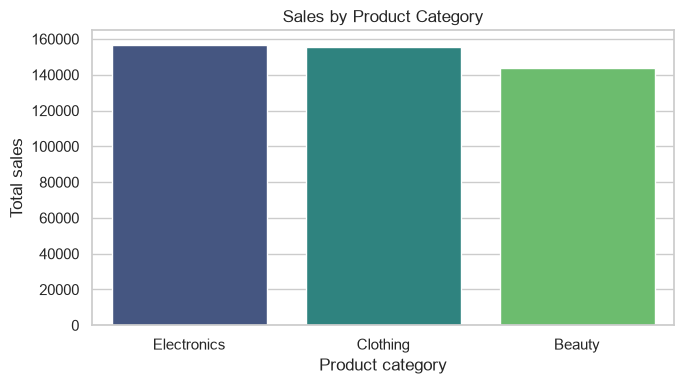

In [5]:
category_sales = (
    df.groupby("Product Category")["Total Amount"]
      .agg(total_sales="sum", transactions="count")
      .sort_values("total_sales", ascending=False)
)
top_categories = category_sales.head(5)
display(top_categories)

plt.figure(figsize=(7, 4))
sns.barplot(data=category_sales.reset_index(), x="Product Category", y="total_sales", hue="Product Category", legend=False, palette="viridis")
plt.title("Sales by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()

## 5. Sales by gender

Gender is present in the dataset, so sales are grouped by the recorded gender values.

,total_sales,transactions
Gender,,
Female,232840,510
Male,223160,490


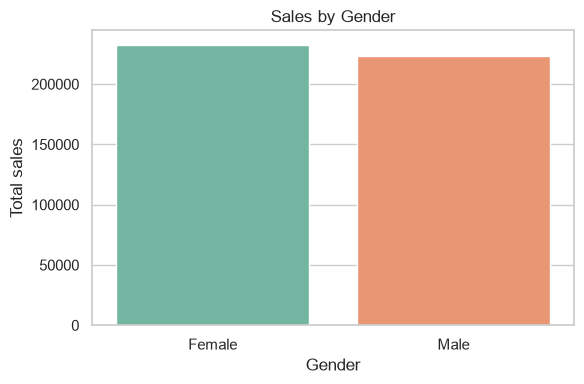

In [6]:
gender_sales = (
    df.groupby("Gender")["Total Amount"]
      .agg(total_sales="sum", transactions="count")
      .sort_values("total_sales", ascending=False)
)
display(gender_sales)

plt.figure(figsize=(6, 4))
sns.barplot(data=gender_sales.reset_index(), x="Gender", y="total_sales", hue="Gender", legend=False, palette="Set2")
plt.title("Sales by Gender")
plt.ylabel("Total sales")
plt.tight_layout()
plt.show()

## 6. Monthly sales trends

The `Date` column supports monthly grouping.

,total_sales
Date,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


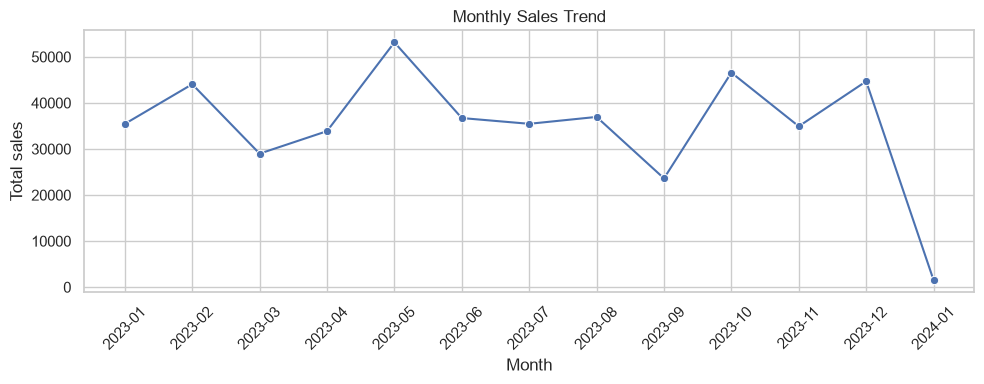

In [7]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Amount"].sum()
display(monthly_sales.to_frame("total_sales"))

plt.figure(figsize=(10, 4))
sns.lineplot(x=monthly_sales.index.astype(str), y=monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Transaction amount distribution

This histogram provides an additional view of the distribution of transaction amounts.

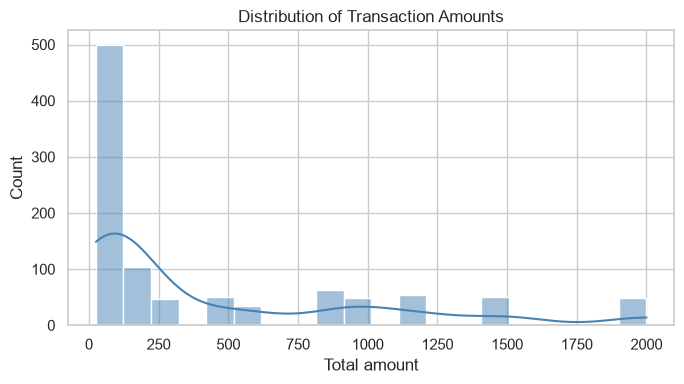

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Total Amount", bins=20, kde=True, color="steelblue")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Total amount")
plt.tight_layout()
plt.show()